# Box Cox Transform

Only apllicable to numbers getter than 0

In [222]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import probplot

In [223]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import PowerTransformer

from sklearn.linear_model import LinearRegression

from sklearn.metrics import accuracy_score, r2_score

In [224]:
df = pd.read_csv("concrete_data.csv")

In [225]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [226]:
df.shape

(1030, 9)

In [227]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [228]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [229]:
x = df.drop(columns=['Strength'])
y = df.iloc[:,-1]

In [230]:
x_train, x_test, y_train, y_test = train_test_split(x, y, 
                                                    test_size=0.1,
                                                    random_state=69)

In [231]:
#apply linear regression
lr = LinearRegression()

lr.fit(x_train,y_train)

y_pred = lr.predict(x_test)

r2_score(y_pred, y_test)

0.5119668036903161

In [232]:
#again with cross val for avg
lr = LinearRegression()

np.mean(cross_val_score(lr, x, y, scoring='r2'))

np.float64(0.4609940491662864)

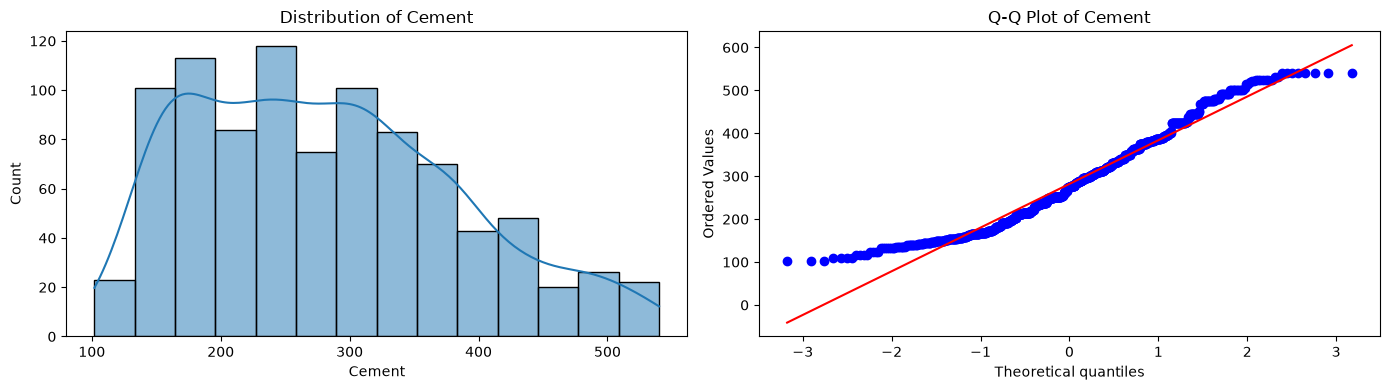

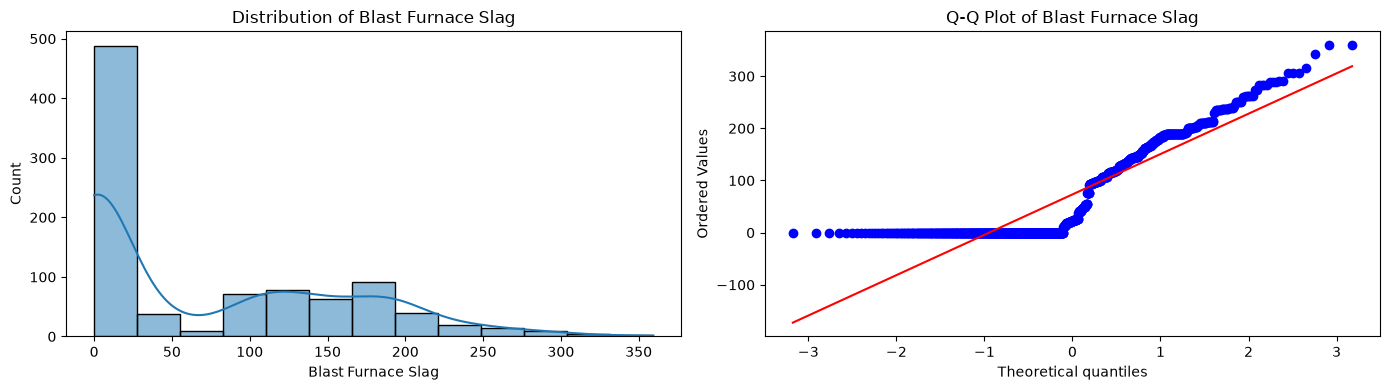

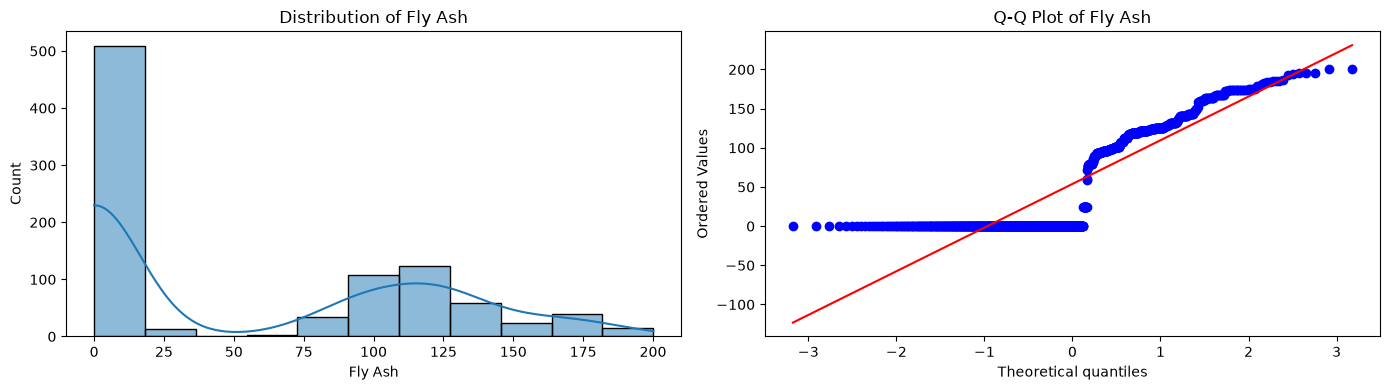

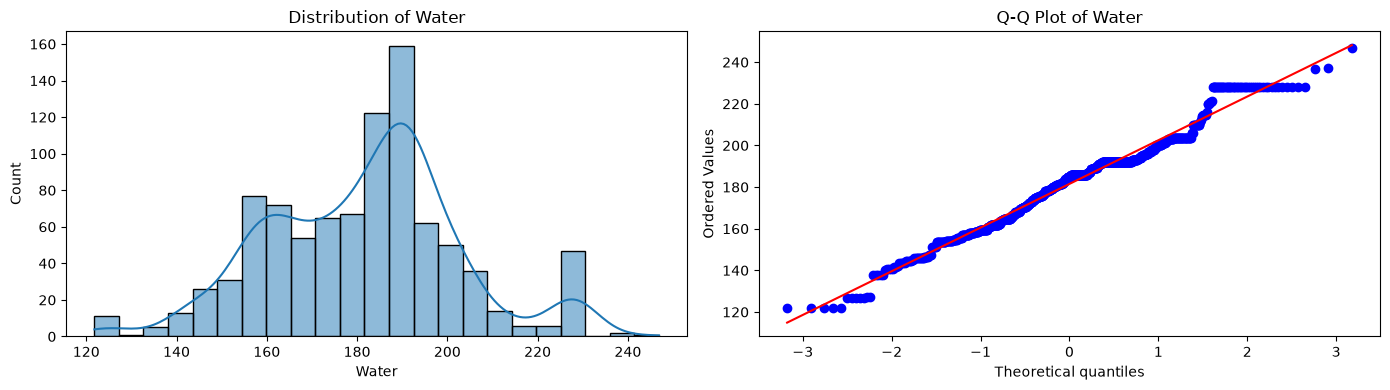

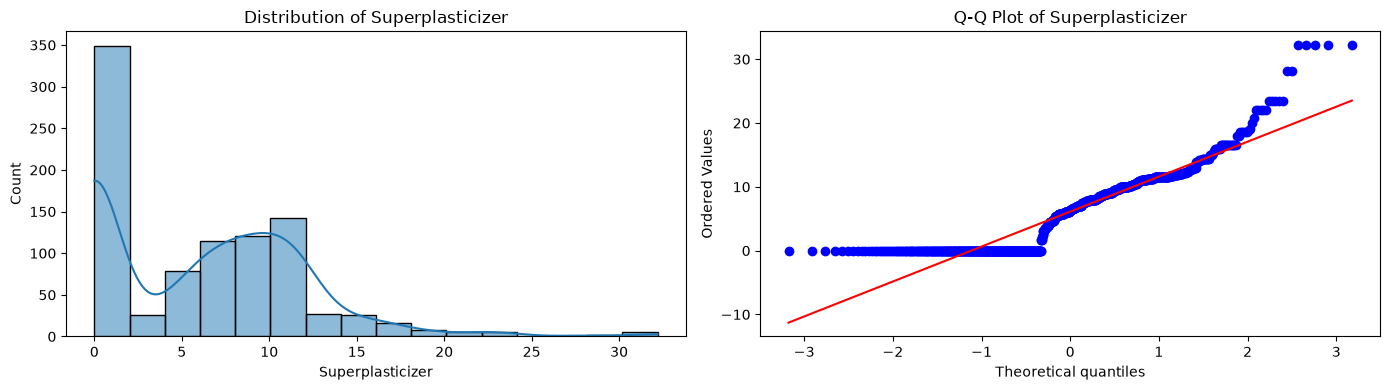

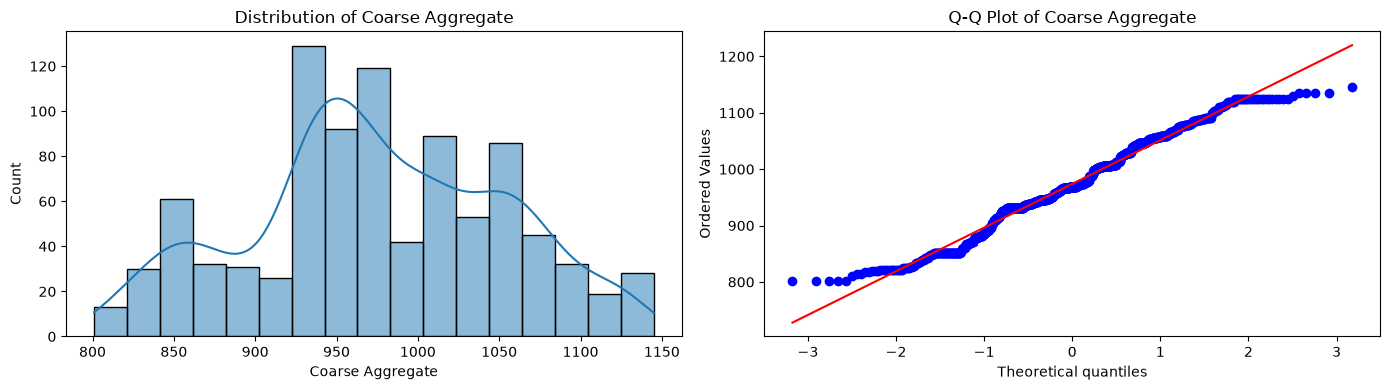

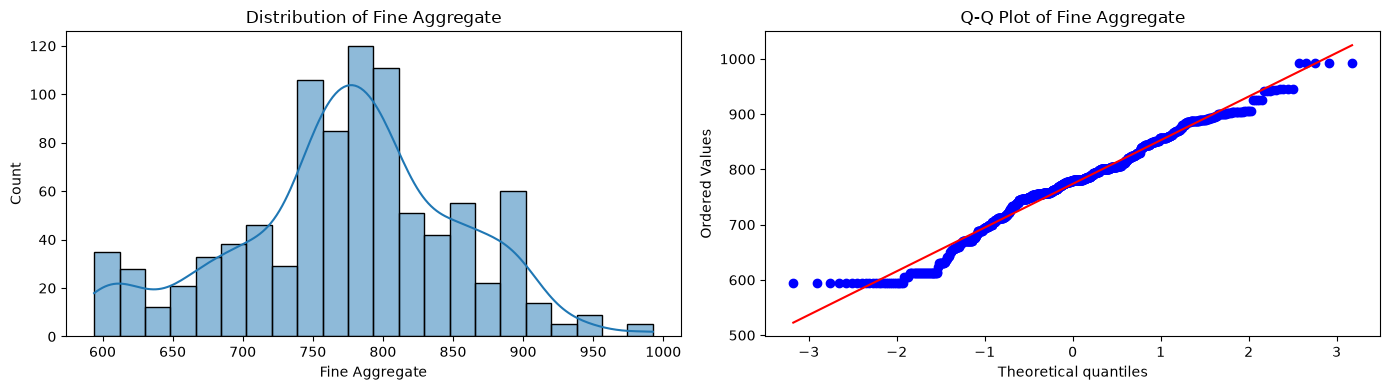

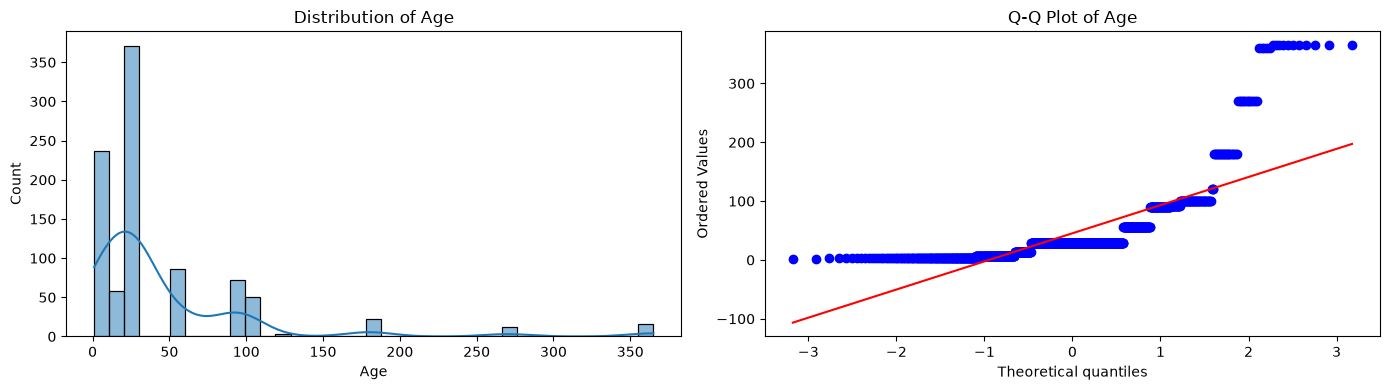

In [233]:
for col in x_train.select_dtypes(include="number").columns:
    plt.figure(figsize=(14, 4))

    plt.subplot(1, 2, 1)
    sns.histplot(x_train[col].dropna(), kde=True)
    plt.title(f"Distribution of {col}")

    plt.subplot(1, 2, 2)
    probplot(x_train[col].dropna(), dist="norm", plot=plt)
    plt.title(f"Q-Q Plot of {col}")

    plt.tight_layout()
    plt.show()

In [235]:
# applying box cox

pt = PowerTransformer(method="box-cox")

x_train_transformed = pt.fit_transform(x_train + 0.00000000001)
x_test_transformed = pt.fit_transform(x_test + 0.00000000001)

pd.DataFrame({'cols':x_train.columns, 'box_cox_lambdas': pt.lambdas_})

,cols,box_cox_lambdas
0,Cement,-0.231533
1,Blast Furnace Slag,0.020715
2,Fly Ash,-0.021454
3,Water,-0.037061
4,Superplasticizer,0.073178
5,Coarse Aggregate,0.906698
6,Fine Aggregate,1.988699
7,Age,-0.035974


In [239]:
# applying LR after transformation

lr = LinearRegression()

lr.fit(x_train_transformed,y_train)

y_pred2 = lr.predict(x_test_transformed)

r2_score( y_test,y_pred2)

0.7994482932484035

In [241]:
# Using cross val score

pt = PowerTransformer(method='box-cox')
X_transformed = pt.fit_transform(x+0.0000001)

lr = LinearRegression()
np.mean(cross_val_score(lr,X_transformed,y,scoring='r2'))

np.float64(0.6658537941434357)

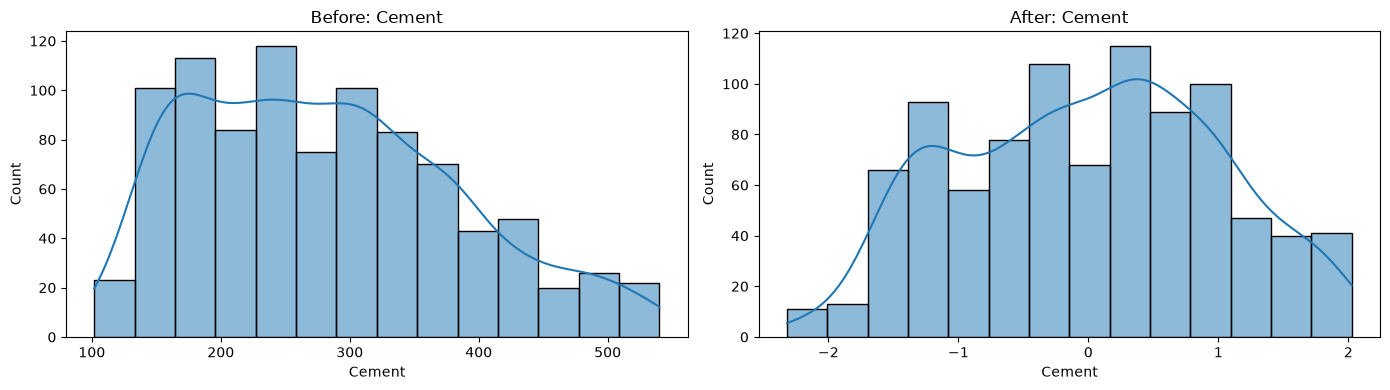

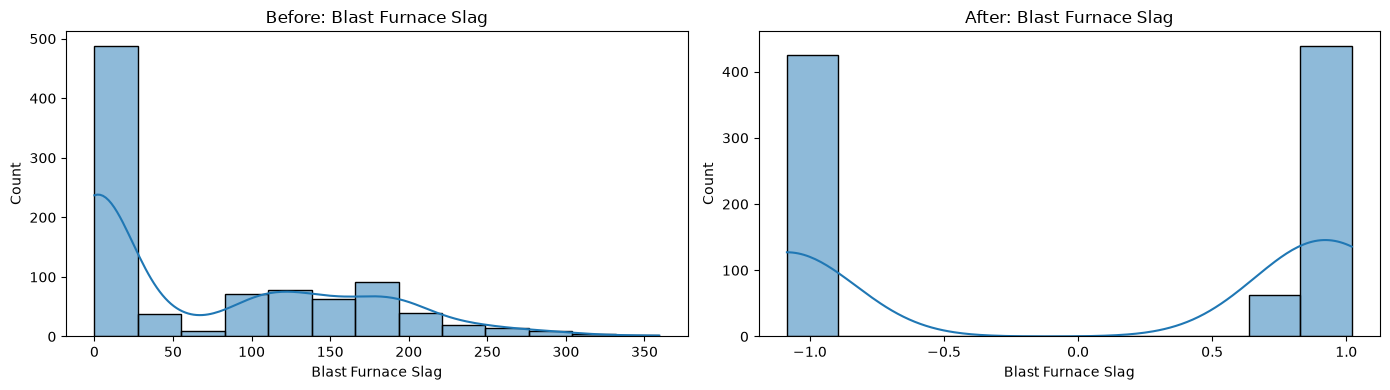

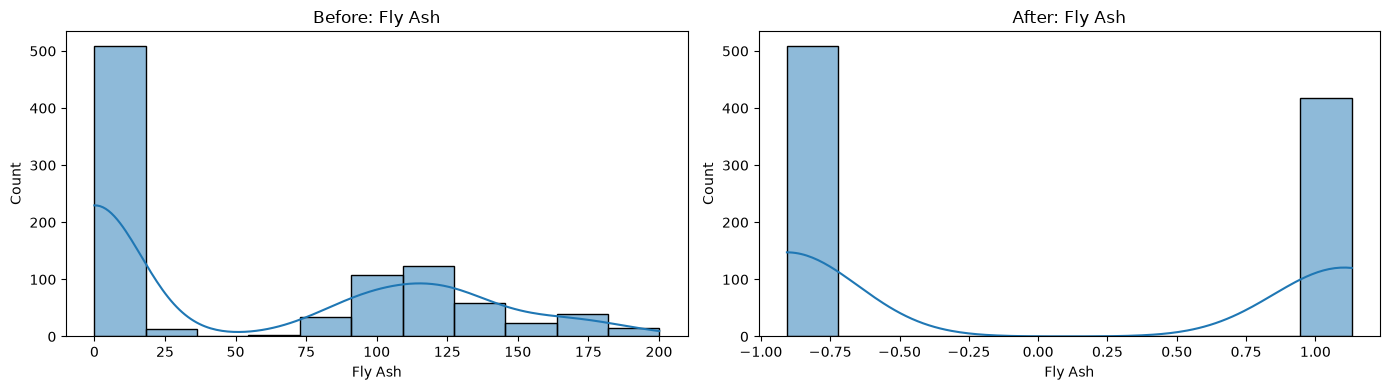

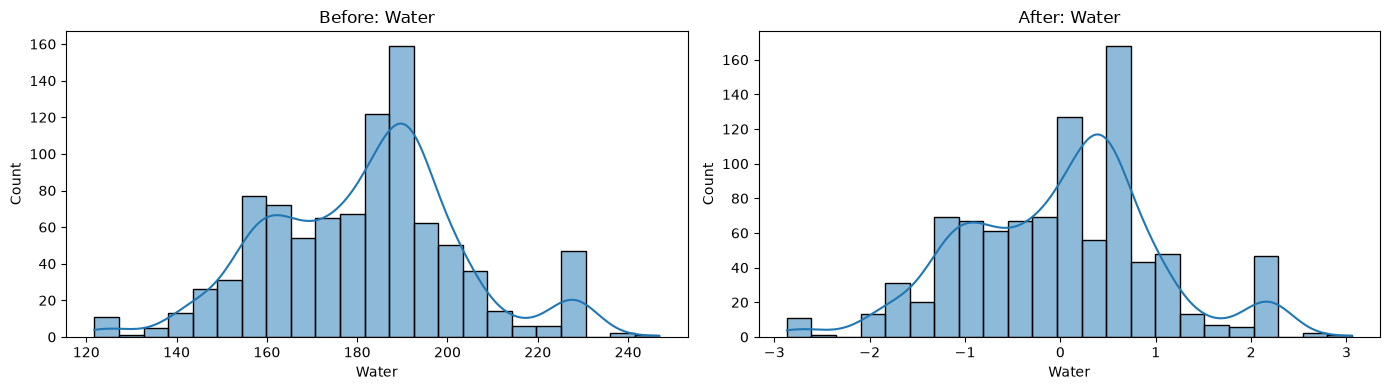

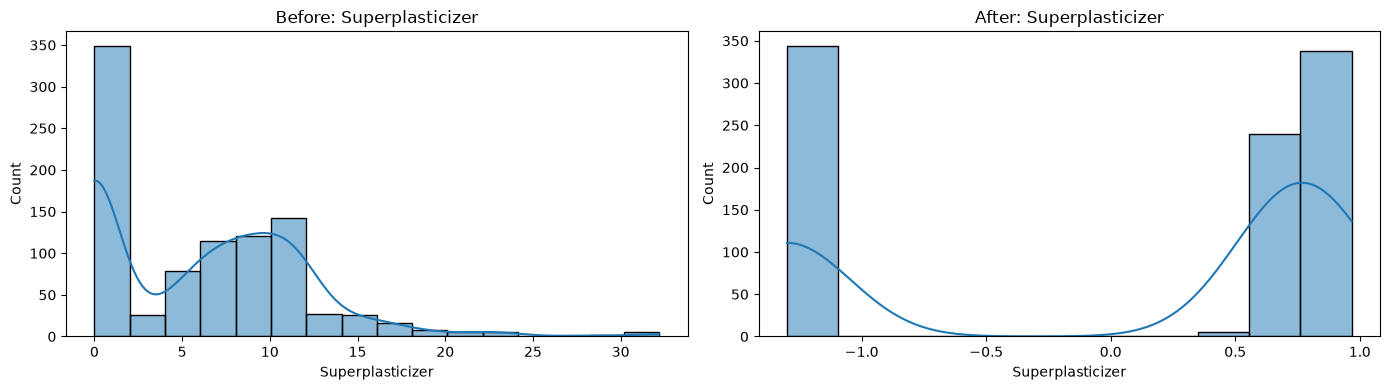

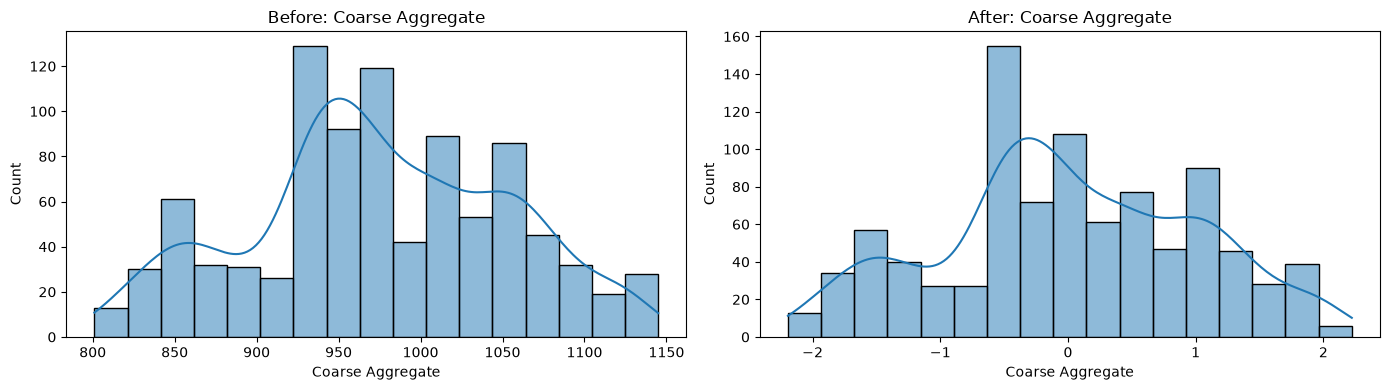

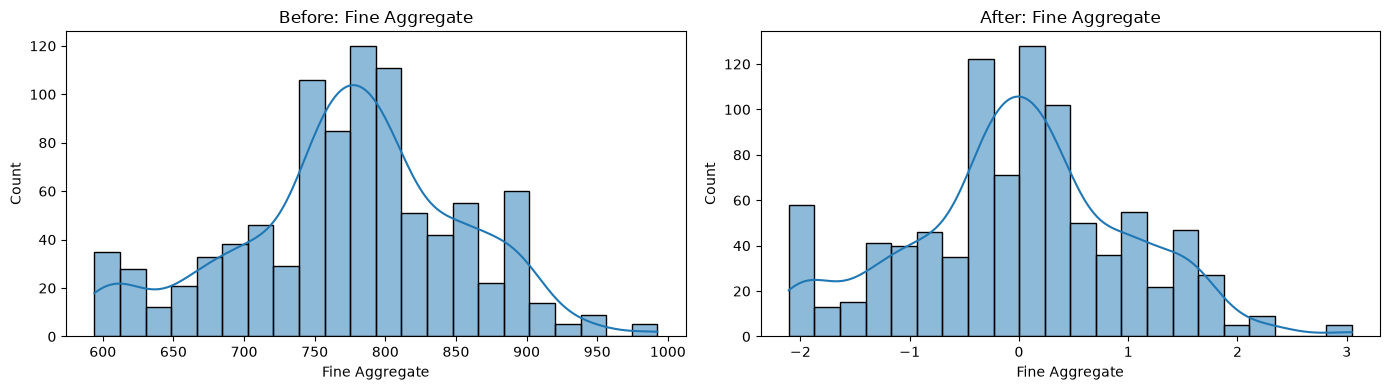

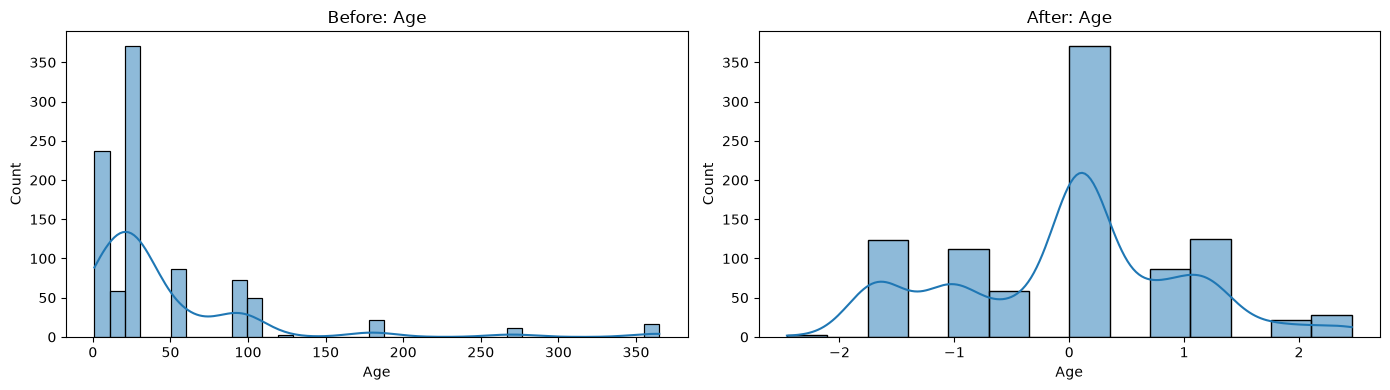

In [244]:
# Before and after comparision for Box-Cox Plot
x_train_transformed = pd.DataFrame(x_train_transformed,columns=x_train.columns)

for col in x_train_transformed.columns:

    plt.figure(figsize=(14, 4))

    # Before transformation
    plt.subplot(1, 2, 1)
    sns.histplot(x_train[col], kde=True)
    plt.title(f"Before: {col}")

    # After transformation
    plt.subplot(1, 2, 2)
    sns.histplot(x_train_transformed[col], kde=True)
    plt.title(f"After: {col}")

    plt.tight_layout()
    plt.show()

In [245]:
# Apply Yeo-Johnson transform

pt1 = PowerTransformer()

x_train_transformed2 = pt1.fit_transform(x_train)
x_test_transformed2 = pt1.transform(x_test)

lr = LinearRegression()
lr.fit(x_train_transformed2,y_train)

y_pred3 = lr.predict(x_test_transformed2)

print(r2_score(y_test,y_pred3))

pd.DataFrame({'cols':x_train.columns,'Yeo_Johnson_lambdas':pt1.lambdas_})

0.8182417740470092


,cols,Yeo_Johnson_lambdas
0,Cement,0.214832
1,Blast Furnace Slag,0.014597
2,Fly Ash,-0.135767
3,Water,0.911626
4,Superplasticizer,0.264725
5,Coarse Aggregate,1.165334
6,Fine Aggregate,1.806998
7,Age,0.012951


In [248]:
# applying yoe johnson
pt1 = PowerTransformer()

x_train_transformed2 = pt1.fit_transform(x_train)
x_test_transformed2 = pt1.fit_transform(x_test)

lr = LinearRegression()
lr.fit(x_train_transformed2, y_train)

y_pred3 = lr.predict(x_test_transformed2)

print(r2_score(y_test, y_pred3))

pd.DataFrame({'cols':x_train.columns,'Yeo_Johnson_lambdas':pt1.lambdas_})

0.8061847517301137


,cols,Yeo_Johnson_lambdas
0,Cement,-0.235859
1,Blast Furnace Slag,0.035224
2,Fly Ash,-0.142589
3,Water,-0.042337
4,Superplasticizer,0.273239
5,Coarse Aggregate,0.906655
6,Fine Aggregate,1.990122
7,Age,-0.087770


In [250]:
# applying cross val score

pt = PowerTransformer()
x_transformed2 = pt.fit_transform(x)

lr = LinearRegression()
np.mean(cross_val_score(lr,x_transformed2,y,scoring='r2'))

np.float64(0.683462515116388)

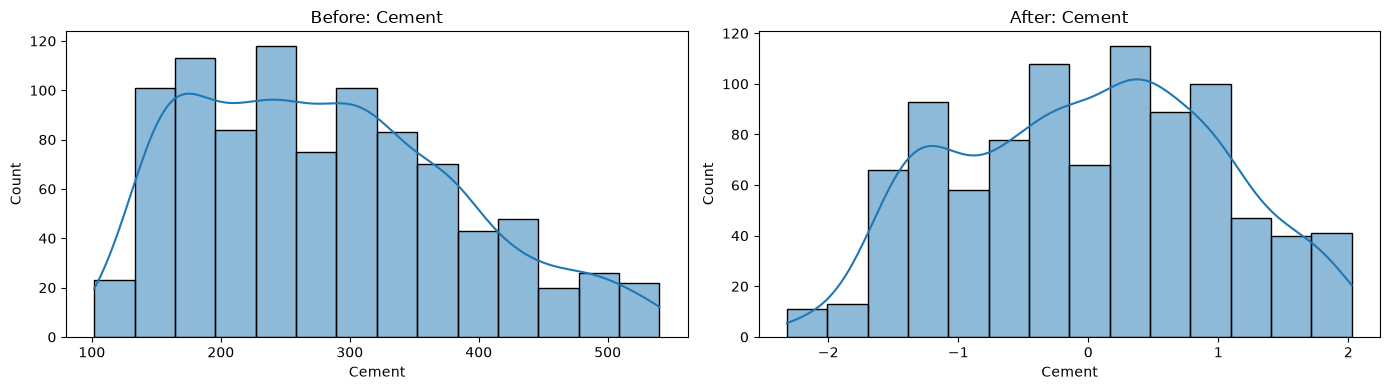

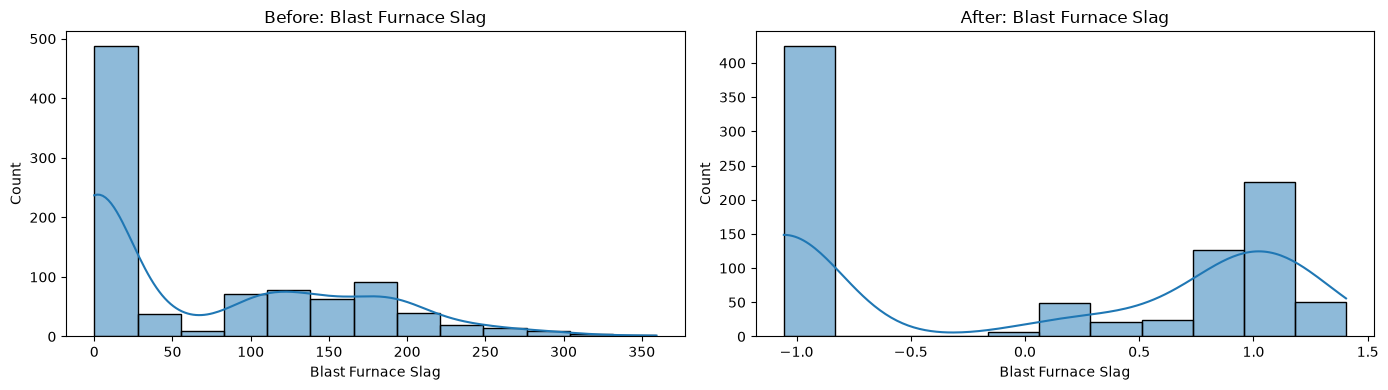

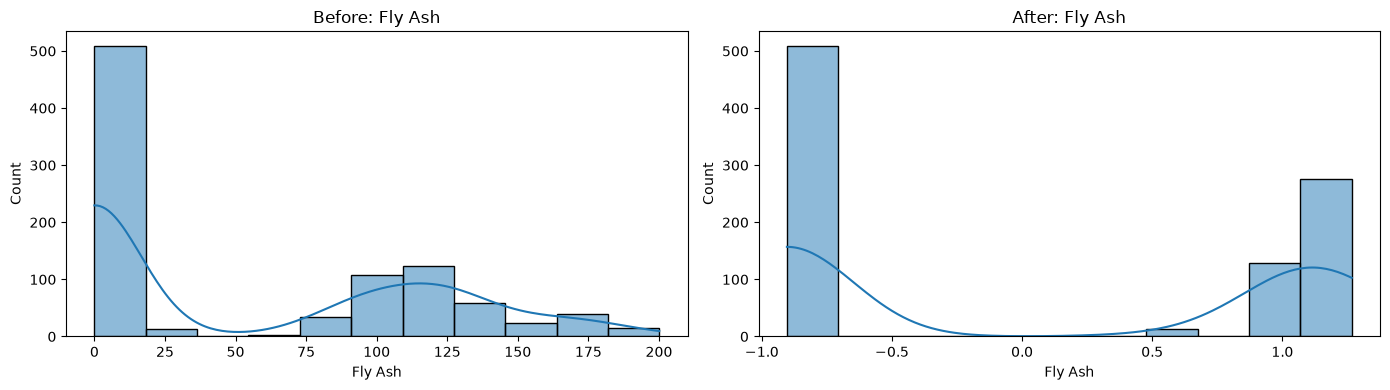

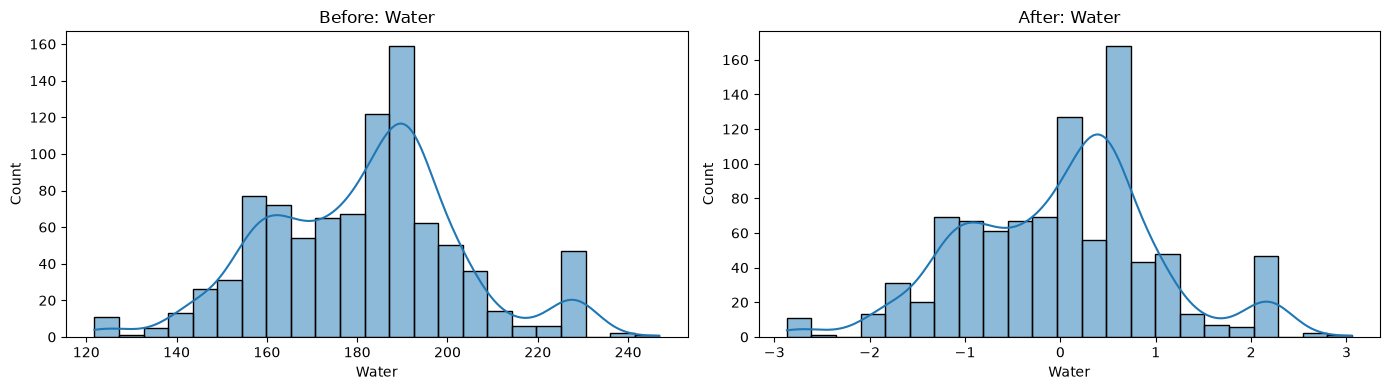

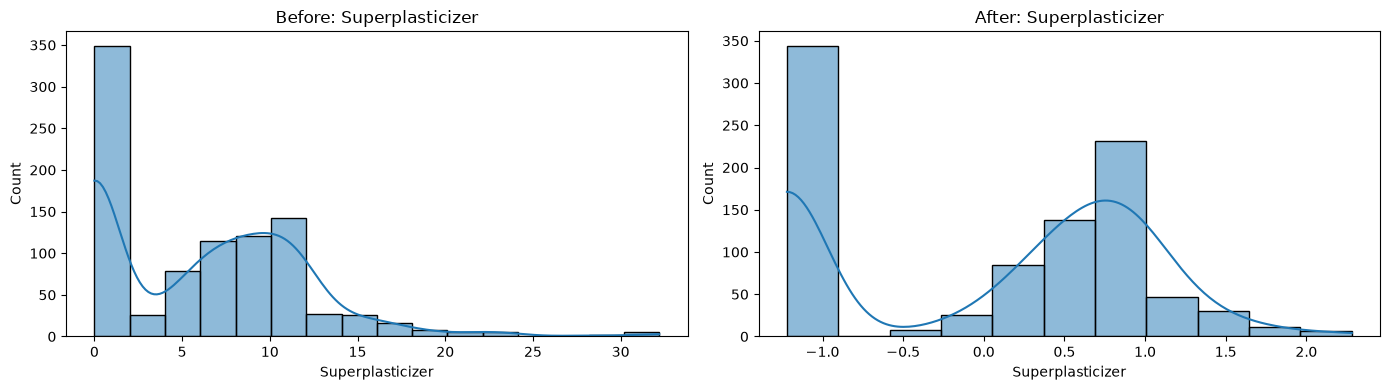

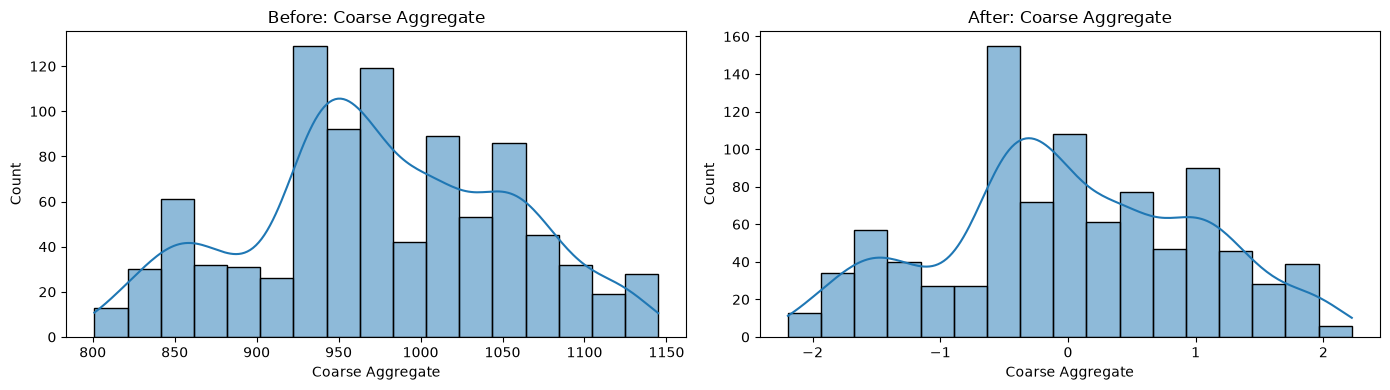

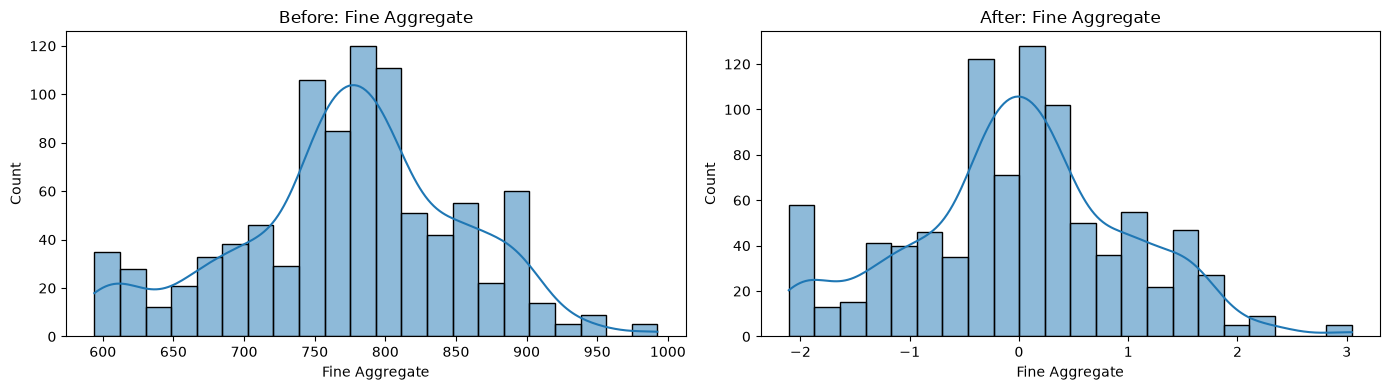

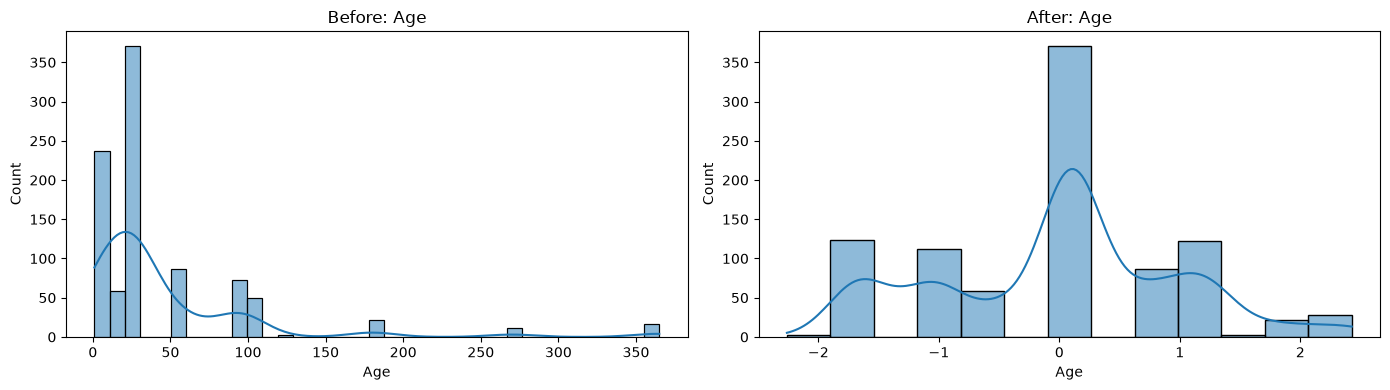

In [253]:
x_train_transformed2 = pd.DataFrame(x_train_transformed2,columns=x_train.columns)
# Before and after comparision for Yeo-Johnson

for col in x_train_transformed2.columns:
    plt.figure(figsize=(14,4))

    # Before transformation
    plt.subplot(1,2,1)
    sns.histplot(x_train[col], kde=True)
    plt.title(f"Before: {col}")

    plt.subplot(1,2,2)
    sns.histplot(x_train_transformed2[col], kde=True)
    plt.title(f"After: {col}")

    plt.tight_layout()
    plt.show()

In [254]:
# Side by side Lambdas
pd.DataFrame({'cols':x_train.columns,'box_cox_lambdas':pt.lambdas_,'Yeo_Johnson_lambdas':pt1.lambdas_})

,cols,box_cox_lambdas,Yeo_Johnson_lambdas
0,Cement,0.169544,-0.235859
1,Blast Furnace Slag,0.016633,0.035224
2,Fly Ash,-0.136480,-0.142589
3,Water,0.808438,-0.042337
4,Superplasticizer,0.264160,0.273239
5,Coarse Aggregate,1.129395,0.906655
6,Fine Aggregate,1.830764,1.990122
7,Age,0.001771,-0.087770
